## KNN Regressor

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Step 1: Generate Synthetic Regression Dataset

`make_regression` generates a random regression problem with controlled noise.

| Parameter | Value | Meaning |
|---|---|---|
| `n_samples` | 1000 | Total number of data points |
| `n_features` | 2 | Number of input features |
| `noise` | 10 | Gaussian noise added to the output: $\epsilon \sim \mathcal{N}(0,\ 10)$ |
| `random_state` | 42 | Fixed seed for reproducibility |

The target variable is a linear combination of features plus noise:

$$y = \mathbf{w}^\top \mathbf{x} + \epsilon, \qquad \epsilon \sim \mathcal{N}(0,\ \sigma^2)$$

Each row of $X$ is a feature vector $\mathbf{x} \in \mathbb{R}^2$. Each entry in $y$ is a continuous target value $y \in \mathbb{R}$.

In [2]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, noise=10, random_state=42)

#### Visualize Dataset Distribution

Plot the feature space colored by the continuous target value, and show the target's histogram.

**What we look for:**
- How smoothly does the target value vary across the feature space?
- Is the relationship approximately linear or non-linear?
- What is the range and shape of the target distribution?

Smooth color gradients across the scatter suggest a well-structured regression problem where KNN can interpolate effectively.

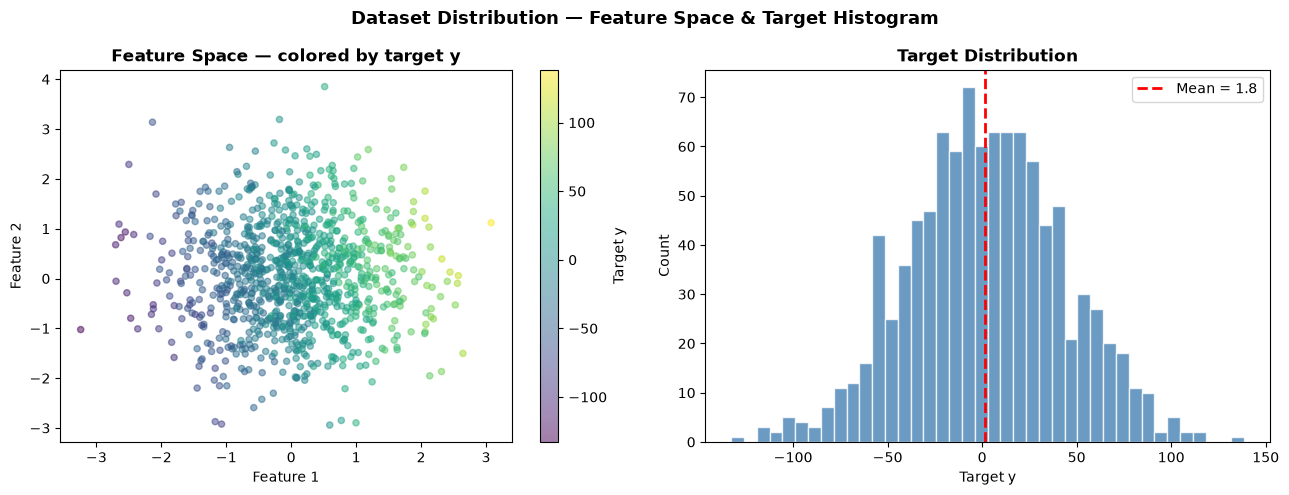

Target range: [-132.8, 138.6]  |  Mean: 1.8  |  Std: 41.3


In [3]:
# --- Plot 1: Dataset Distribution — Feature Space colored by y, and Target Histogram ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc = axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', alpha=0.5, s=20)
plt.colorbar(sc, ax=axes[0], label='Target y')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].set_title('Feature Space — colored by target y', fontweight='bold')

axes[1].hist(y, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Target y')
axes[1].set_ylabel('Count')
axes[1].set_title('Target Distribution', fontweight='bold')
axes[1].axvline(y.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean = {y.mean():.1f}')
axes[1].legend()

plt.suptitle('Dataset Distribution — Feature Space & Target Histogram',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Target range: [{y.min():.1f}, {y.max():.1f}]  |  Mean: {y.mean():.1f}  |  Std: {y.std():.1f}')

### Step 2: Split into Training and Test Sets

Divide the dataset into a **training set** (used to fit the model) and a **test set** (used to evaluate generalization).

$$n_{\text{train}} = 0.67 \times 1000 = 670\ \text{samples}, \qquad n_{\text{test}} = 0.33 \times 1000 = 330\ \text{samples}$$

| Split | Size | Purpose |
|---|---|---|
| `X_train`, `y_train` | 670 samples | KNN stores these points and target values |
| `X_test`, `y_test` | 330 samples | Held out — evaluated only after training |

> [!WARNING]
> KNN memorizes the entire training set. Evaluating on training data gives an unrealistically optimistic score. The test set must remain **unseen** until the final evaluation step.

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

#### Visualize Train-Test Split

Compare the spatial coverage of training and test points, both colored by their continuous target values.

**What we look for:**
- Are test points well distributed throughout the feature space (not clustered in one region)?
- Does the target value distribution look similar in both splits?

Both splits should cover similar regions. If the test set has gaps not covered by training points, KNN will extrapolate from distant neighbors — increasing error.

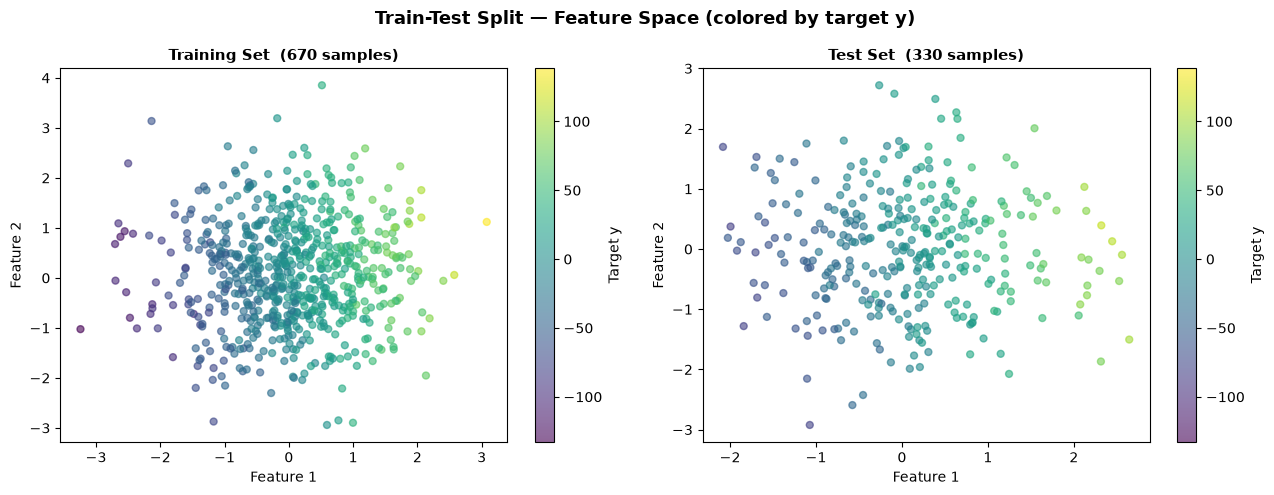

In [5]:
# --- Plot 2: Train / Test Split — Feature Space colored by continuous target y ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
vmin, vmax = y.min(), y.max()

for ax, (X_data, y_data, title) in zip(axes, [
    (X_train, y_train, f'Training Set  ({len(y_train)} samples)'),
    (X_test,  y_test,  f'Test Set  ({len(y_test)} samples)')
]):
    sc = ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap='viridis',
                    alpha=0.6, s=25, vmin=vmin, vmax=vmax)
    plt.colorbar(sc, ax=ax, label='Target y')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')

plt.suptitle('Train-Test Split — Feature Space (colored by target y)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Step 3: Instantiate and Train the KNN Regressor

**KNN training (`fit()`)** is a form of **lazy learning** — no traditional parameters are optimized.

**What happens during `fit()`:**
- Stores all training features (`X_train`) and target values (`y_train`)
- Depending on `algorithm`, may construct a search structure (KD-tree or Ball tree) to speed up future distance queries
- Does **not** learn regression coefficients like linear regression

> [!NOTE]
> Hyperparameters such as `n_neighbors`, `weights`, and `metric` must still be selected before fitting — typically using cross-validation (see Plot 5).

---

**KNN Regression — prediction rule for a query point $\mathbf{x}$:**

**Step 1 — Compute Euclidean distance** to every training point:

$$d(\mathbf{x},\ \mathbf{x}_i) = \sqrt{\sum_{j=1}^{d}(x_j - x_{ij})^2}$$

**Step 2 — Identify the $k$ nearest neighbors:**

$$\mathcal{N}_k(\mathbf{x}) = \{k\ \text{training points with smallest}\ d(\mathbf{x}, \mathbf{x}_i)\}$$

**Step 3 — Average the target values** (continuous prediction):

$$\hat{f}(\mathbf{x}) = \frac{1}{k} \sum_{i \in \mathcal{N}_k(\mathbf{x})} y_i$$

Unlike classification (majority vote counts), regression **averages** the target values of the $k$ neighbors to get a continuous output.

---

**How this creates the regression surface:**

**For ONE test point:**
- Compute distance FROM that test point TO each of the 670 training points
- Find the $k=6$ training points with smallest distances (nearest neighbors)
- Get their 6 target values: $y_1, y_2, \ldots, y_6$
- Compute average: $\hat{f}(\mathbf{x}) = \frac{1}{6}(y_1 + y_2 + \cdots + y_6)$
- Result: one continuous prediction value

**For a MESH GRID (thousands of points) — This creates the surface visualization:**
1. Create dense grid of points covering the feature space (e.g., with $h = 0.1$: a 70×70 mesh ≈ 4,900 points)
2. **For each grid point** $(\mathbf{x}^*)$:
   - Calculate distance FROM this grid point TO each of the 670 training points
   - Find the $k=6$ nearest training points
   - Average their target values to get one continuous prediction
3. Assign a **heatmap color** to each grid point based on its predicted value $\hat{f}(\mathbf{x}^*)$:
   - Low predicted values (e.g., -100) → dark blue
   - Medium predicted values (e.g., 0) → green/yellow
   - High predicted values (e.g., +100) → bright yellow
4. Plot all ~4,900 colored points on the graph → creates a smooth **continuous surface**

**Example — Averaging applied to three grid points:**

| Grid Point | Distance to Training Points | $k=6$ Nearest Neighbors' Values | Average Prediction |
|---|---|---|---|
| $(0.5, 1.0)$ | $d_1=0.2, d_2=0.3, \ldots, d_{670}=50.1$ | $\{10.2, 9.8, 10.5, 10.1, 9.9, 10.3\}$ | $\hat{f} = 10.13$ (Color: blue) |
| $(2.0, 3.0)$ | $d_1=2.1, d_2=2.5, \ldots, d_{670}=48.0$ | $\{25.1, 24.9, 25.3, 25.0, 24.8, 25.2\}$ | $\hat{f} = 25.05$ (Color: yellow) |
| $(-1.0, 0.5)$ | $d_1=1.5, d_2=1.8, \ldots, d_{670}=52.3$ | $\{-5.2, -5.5, -5.1, -5.3, -5.4, -5.0\}$ | $\hat{f} = -5.25$ (Color: dark) |

---

**What surface smoothness tells you:**

| $k$ value | Typical surface | Typical behaviour |
|---|---|---|
| Small $k$ | Jagged, patchwork | Sensitive to individual points — high variance, potential overfitting |
| Large $k$ | Smooth, continuous | More averaging, lower variance — potential underfitting |

> [!IMPORTANT]
> A smoother surface does **not** automatically mean a better model.
> Large $k$ reduces variance but increases bias — the model may underfit.
> **Use cross-validation** (Plot 5) to determine the appropriate $k$.

| Parameter | Value | Meaning |
|---|---|---|
| `n_neighbors` | 6 | Average the 6 nearest neighbors' target values |
| `algorithm` | `'auto'` | Scikit-learn picks brute-force, KD-tree, or Ball tree automatically |

In [6]:
from sklearn.neighbors import KNeighborsRegressor

In [7]:
regressor=KNeighborsRegressor(n_neighbors=6,algorithm='auto')
regressor.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",6
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


#### KNN Regression Prediction Surface

Visualize what the trained model predicts across the full feature space by evaluating on a dense mesh grid.

**Left** — predicted target value at every grid point (the learned surface).  
**Right** — actual target values in the same space for comparison.

> [!IMPORTANT]
> **KNN Regressor does NOT create a decision boundary.**
>
> | | KNN Classifier | KNN Regressor |
> |---|---|---|
> | **Output** | Discrete class labels (0 or 1) | Continuous values (e.g., -150 to +150) |
> | **Visualization** | **Decision Boundary** — a line where prediction flips | **Prediction Surface** — smooth heatmap, NO boundary line |
> | **Colors** | Discrete (blue region vs orange region) | Continuous gradient (dark blue → bright yellow) |
> | **Plot function** | `plt.contour()` draws the boundary line | `plt.contourf()` fills the whole surface |
> | **Where is the boundary?** | Where color changes from one class to another | **No boundary** — predictions vary smoothly everywhere |

---

**1. What is the step size ($h = 0.1$) in regression?**

- Just like classification, the ***step size controls*** how **densely** we ***create grid points for visualization.*** 
- It is a **visualization parameter** — it ***does NOT change*** the ***KNN model*** or its ***predictions at any given point.***

Regression typically uses a slightly larger $h$ than classification (e.g., $h = 0.1$ instead of $h = 0.05$) because:
- The output is **continuous** — small differences in predicted value are shown by color gradient, not a sharp line
- `contourf` with `levels=50` already smooths the surface visually
- A finer grid ($h = 0.05$) would use 4× more memory and computation with minimal visual improvement

| Step size | Grid density | Surface quality |
|---|---|---|
| $h = 1.0$ | Very coarse | Blocky, rough surface |
| $h = 0.5$ | Moderate | Visible steps |
| $h = 0.1$ | Fine | Smooth surface ✓ (used here) |
| $h = 0.05$ | Very fine | Marginally smoother, 4× slower |

> [!IMPORTANT]
> **$h$ controls how many locations we evaluate to draw the surface.**
> **$k$ controls how many neighbours are averaged at each location.**
> They are completely independent parameters.

---

**2. How many grid points are generated?**

Using `np.arange` with $h = 0.1$ and a margin of $\pm 0.5$ on a feature range of approximately $-3$ to $3$:

$$\text{Points per axis} = \frac{3.5 - (-3.5)}{0.1} = 70 \approx 70$$

$$\text{Total grid points} \approx 70 \times 70 = \boxed{4{,}900 \text{ grid points}}$$

Each of these ~4,900 points gets one **continuous** predicted value from the KNN regressor.

---

**3. For each grid point, do we calculate distance to all training samples?**

**Yes — for brute-force search.** For every grid point, KNN calculates its Euclidean distance to all 670 training samples, then selects the $k=6$ closest and averages their target values.

**Example — one grid point $G_1 = (1.0, 0.5)$:**

1. Compute distance to all 670 training points
2. Sort distances, select the 6 smallest
3. Average their target values: e.g., $\{20.1, 18.9, 21.3, 19.7, 20.5, 19.4\}$ → $\hat{f} = 20.0$
4. Assign heatmap color based on $\hat{f}$ (not a class label — a continuous number)

Then move to $G_2$, repeat — for all ~4,900 grid points.

---

**4. Total number of distance calculations**

$$\text{Distance calculations} = \text{Grid points} \times \text{Training samples} \approx 4{,}900 \times 670 = \boxed{3{,}283{,}000}$$

That is **~3.3 million distance calculations** — just for the visualization.

> [!NOTE]
> This describes brute-force search. If `algorithm='auto'` selects a KD-tree or Ball-tree, scikit-learn may reduce this by pruning branches that cannot contain the nearest neighbors.

---

**5. How the prediction surface is built — step by step**

**Step 1: Create a dense mesh grid** covering the 2D feature space with step size $h = 0.1$:
$$\text{Grid points: } (\mathbf{x}^*_1, \mathbf{x}^*_2), (\mathbf{x}^*_3, \mathbf{x}^*_4), \ldots$$

**Step 2: For each grid point, apply the averaging formula:**

For every grid point $\mathbf{x}^*$, repeat:
1. Compute Euclidean distance to all training points:
   $$d_i = \sqrt{(x^*_1 - x_{i1})^2 + (x^*_2 - x_{i2})^2}$$
2. Find $k = 6$ nearest training points with smallest distances
3. Average their target values:
   $$\hat{f}(\mathbf{x}^*) = \frac{1}{6}\sum_{i \in \mathcal{N}_6(\mathbf{x}^*)} y_i$$

**Step 3: Assign a heatmap color** to each grid point based on its predicted value:
- Low values (e.g., $-150$) → dark blue
- Medium values (e.g., $0$) → green / yellow
- High values (e.g., $+150$) → bright yellow

**Step 4: Plot all grid points** — `plt.contourf()` fills the entire surface with 50 smooth color levels. There is **no boundary line** — the whole surface is one continuous gradient.

---

**6. The Python code (what it does internally)**

```python
import numpy as np

# Step 1: Define the feature-space limits
h = 0.1
x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# Step 2: Generate the mesh grid
xx, yy_grid = np.meshgrid(
    np.arange(x0_min, x0_max, h),
    np.arange(x1_min, x1_max, h))

# Step 3: Predict a continuous value for every grid point
Z = regressor.predict(np.c_[xx.ravel(), yy_grid.ravel()])
                # scikit-learn averages k=6 neighbors internally for each point

# Step 4: Reshape predictions back into grid format
Z = Z.reshape(xx.shape)

# Step 5: Fill the surface with a continuous heatmap (no boundary line)
plt.contourf(xx, yy_grid, Z, levels=50, cmap='viridis')
```

> [!NOTE]
> The key difference from classification: `regressor.predict()` returns **continuous values** (not class labels), and `plt.contourf()` fills the whole surface as a smooth gradient — there is no `plt.contour()` call to draw a boundary.

---

**7. Full parameter summary**

| Parameter | What it controls |
|---|---|
| Training samples (670) | Number of existing examples KNN memorizes |
| Features (2) | Dimensions of the feature space |
| $k = 6$ | Number of neighbours whose target values are **averaged** |
| Step size $h = 0.1$ | **Density** of the visualization grid — smaller = smoother surface |

**What surface smoothness tells you:**

| $k$ value | Typical surface | Typical behaviour |
|---|---|---|
| Small $k$ | Jagged, patchwork | Sensitive to individual points — high variance, potential overfitting |
| Large $k$ | Smooth, continuous | More averaging, lower variance — potential underfitting |

> [!IMPORTANT]
> A smoother surface does **not** automatically mean a better model.
> Large $k$ reduces variance but increases bias — the model may underfit.
> **Use cross-validation** (Plot 5) to determine the appropriate $k$.

The two plots should closely resemble each other — large differences reveal where the model is over-fitting or under-fitting.

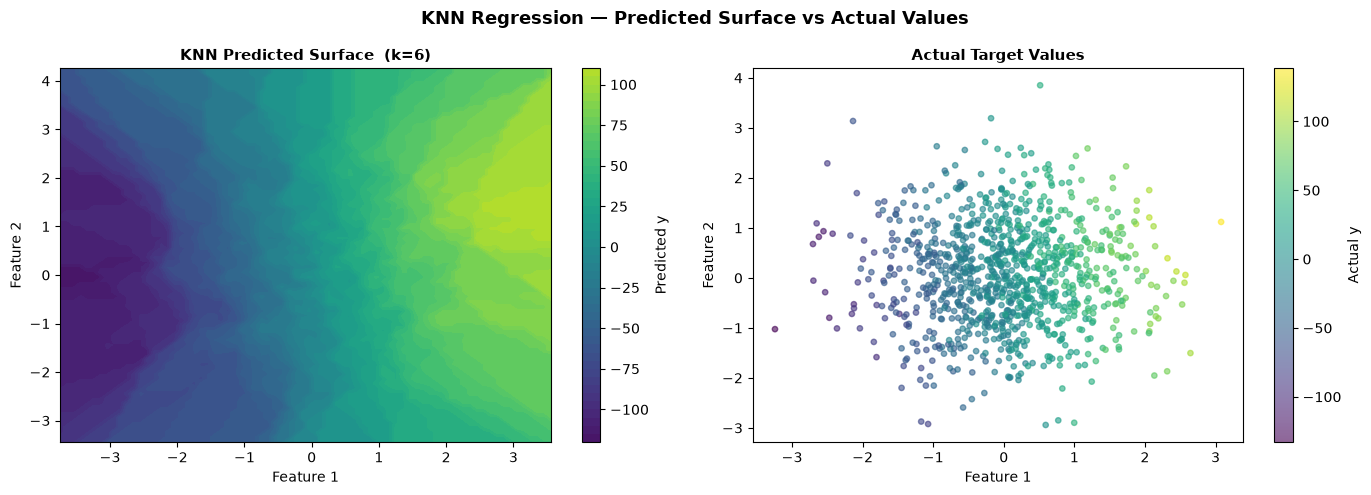

In [8]:
# --- Plot 3: KNN Regression Prediction Surface vs Actual Values ---
h = 0.1
x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy_grid = np.meshgrid(np.arange(x0_min, x0_max, h),
                           np.arange(x1_min, x1_max, h))

Z = regressor.predict(np.c_[xx.ravel(), yy_grid.ravel()]).reshape(xx.shape)
vmin_all, vmax_all = y.min(), y.max()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cf = axes[0].contourf(xx, yy_grid, Z, levels=50, cmap='viridis',
                       vmin=vmin_all, vmax=vmax_all)
plt.colorbar(cf, ax=axes[0], label='Predicted y')
axes[0].set_title('KNN Predicted Surface  (k=6)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')

sc = axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', alpha=0.6, s=15,
                      vmin=vmin_all, vmax=vmax_all)
plt.colorbar(sc, ax=axes[1], label='Actual y')
axes[1].set_title('Actual Target Values', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')

plt.suptitle('KNN Regression — Predicted Surface vs Actual Values',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Step 4: Make Predictions on the Test Set

Apply the trained regressor to all 330 test points. For each test point $\mathbf{x}_i \in X_{\text{test}}$, KNN:

1. Computes distances to all 670 training points
2. Selects the $k = 6$ nearest neighbors
3. Returns the mean of their target values

$$\hat{y}_i = \frac{1}{6}\sum_{j \in \mathcal{N}_6(\mathbf{x}_i)} y_j, \qquad i = 1, \ldots, 330$$

The result `y_pred` is an array of 330 continuous predicted values $\in \mathbb{R}$.

In [9]:
y_pred=regressor.predict(X_test)

#### Actual vs Predicted and Residuals Plot

Diagnose prediction quality on the 330 held-out test points.

**Left — Actual vs Predicted:** Points close to the red dashed diagonal indicate accurate predictions. Systematic deviation above or below the diagonal signals model bias.  
**Right — Residuals ($y - \hat{y}$):** Residuals should scatter randomly around zero with no pattern. A fan shape indicates heteroscedasticity; a curve means the model is missing non-linear structure.

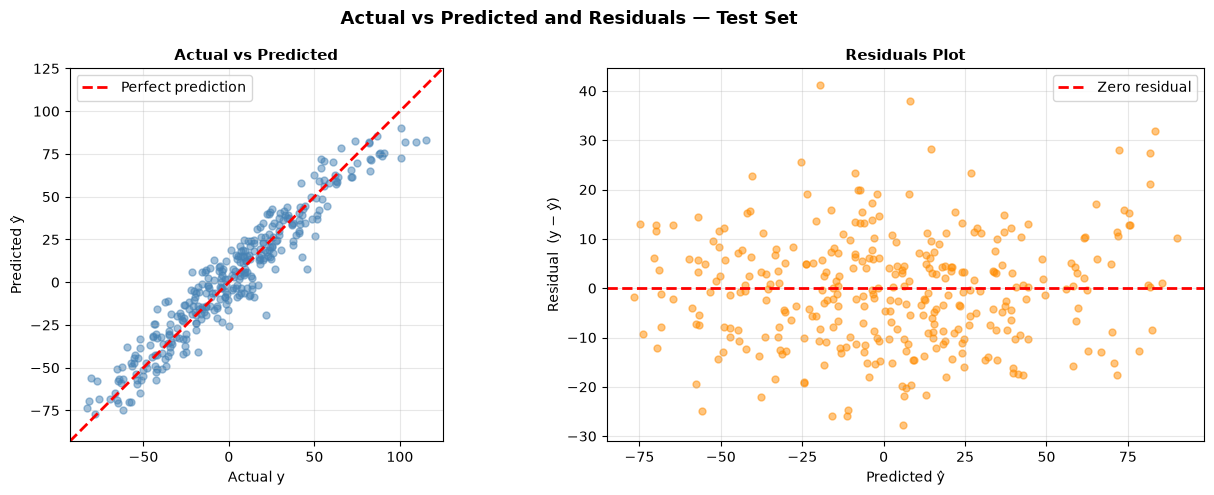

Mean residual: -0.4585  (should be ≈ 0)
Residual std : 11.2804


In [10]:
# --- Plot 4: Actual vs Predicted + Residuals Plot ---
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

lo = min(y_test.min(), y_pred.min()) - 10
hi = max(y_test.max(), y_pred.max()) + 10
axes[0].scatter(y_test, y_pred, alpha=0.5, s=25, color='steelblue')
axes[0].plot([lo, hi], [lo, hi], 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual y')
axes[0].set_ylabel('Predicted ŷ')
axes[0].set_title('Actual vs Predicted', fontsize=11, fontweight='bold')
axes[0].set_xlim(lo, hi)
axes[0].set_ylim(lo, hi)
axes[0].legend()
axes[0].set_aspect('equal')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_pred, residuals, alpha=0.5, s=25, color='darkorange')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2, label='Zero residual')
axes[1].set_xlabel('Predicted ŷ')
axes[1].set_ylabel('Residual  (y − ŷ)')
axes[1].set_title('Residuals Plot', fontsize=11, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Actual vs Predicted and Residuals — Test Set',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Mean residual: {residuals.mean():.4f}  (should be ≈ 0)')
print(f'Residual std : {residuals.std():.4f}')

### Step 5: Evaluate the Regression Model

Measure regression performance using $R^2$, **MAE**, and **MSE**.

**$R^2$ (Coefficient of Determination)** — proportion of variance in $y$ explained by the model:

$$R^2 = 1 - \frac{\displaystyle\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\displaystyle\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

**Mean Absolute Error (MAE)** — average magnitude of prediction errors:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$$

**Mean Squared Error (MSE)** — average squared error (penalizes large errors more heavily):

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

| Metric | Ideal Value | Direction | Sensitive to Outliers? |
|---|---|---|---|
| $R^2$ | 1.0 | Higher is better | Yes |
| MAE | 0 | Lower is better | No |
| MSE | 0 | Lower is better | Yes |

In [11]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [12]:
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))

0.9189275159979495
9.009462452972217
127.45860414317289


### Task: Find the Best K using Cross-Validation

Use 5-fold cross-validation to compare KNN Regressor performance for $k = 1$ to $k = 20$.

**Goal:** Find the value of $k$ that maximizes the validation $R^2$ score without overfitting.

| k is too small | k is optimal | k is too large |
|---|---|---|
| Overfits — high variance | Best generalization | Underfits — high bias |
| Train $R^2 \approx 1.0$ | Train and CV $R^2$ are close | Both train and CV $R^2$ are lower |

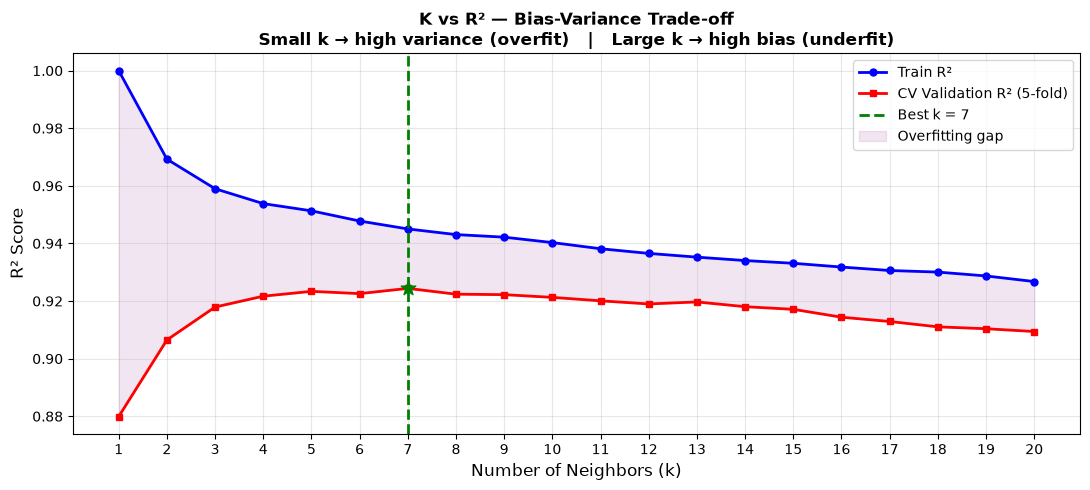

Best k = 7  |  CV R² = 0.9244

  k    Train R²       CV R²
----------------------------
  1      1.0000      0.8799
  2      0.9693      0.9065
  3      0.9590      0.9179
  4      0.9538      0.9217
  5      0.9513      0.9234
  6      0.9478      0.9226
  7      0.9450      0.9244 ◄ best
  8      0.9431      0.9224
  9      0.9422      0.9222
 10      0.9403      0.9213
 11      0.9382      0.9201
 12      0.9365      0.9190
 13      0.9353      0.9197
 14      0.9341      0.9180
 15      0.9331      0.9171
 16      0.9318      0.9144
 17      0.9306      0.9129
 18      0.9301      0.9111
 19      0.9287      0.9104
 20      0.9268      0.9094


In [13]:
# --- Plot 5: K vs R² — Bias-Variance Trade-off (5-fold CV) ---
from sklearn.model_selection import cross_val_score

k_range  = range(1, 21)
train_r2 = []
cv_r2    = []

for k in k_range:
    knn_k = KNeighborsRegressor(n_neighbors=k, algorithm='auto')
    knn_k.fit(X_train, y_train)
    train_r2.append(knn_k.score(X_train, y_train))
    cv_r2.append(cross_val_score(knn_k, X_train, y_train, cv=5, scoring='r2').mean())

best_k = list(k_range)[np.argmax(cv_r2)]

plt.figure(figsize=(11, 5))
plt.plot(list(k_range), train_r2, 'b-o', label='Train R²',
         linewidth=2, markersize=5)
plt.plot(list(k_range), cv_r2,   'r-s', label='CV Validation R² (5-fold)',
         linewidth=2, markersize=5)
plt.axvline(x=best_k, color='green', linestyle='--', linewidth=2,
            label=f'Best k = {best_k}')
plt.scatter([best_k], [max(cv_r2)], color='green', zorder=5, s=120, marker='*')
plt.fill_between(list(k_range), train_r2, cv_r2,
                 alpha=0.1, color='purple', label='Overfitting gap')

plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('R² Score', fontsize=12)
plt.title('K vs R² — Bias-Variance Trade-off\n'
          'Small k → high variance (overfit)   |   Large k → high bias (underfit)',
          fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

print(f'Best k = {best_k}  |  CV R² = {max(cv_r2):.4f}')
print()
print(f'{"k":>3}  {"Train R²":>10}  {"CV R²":>10}')
print('-' * 28)
for k, tr, cv in zip(k_range, train_r2, cv_r2):
    marker = ' ◄ best' if k == best_k else ''
    print(f'{k:>3}  {tr:>10.4f}  {cv:>10.4f}{marker}')

---

<p align="center">
  ⬅️ <strong>Previous:</strong> <a href="./04.3%20KNN%20Regressor%20From%20Scratch.ipynb">04.3 KNN Regressor From Scratch</a> &nbsp;&nbsp;|&nbsp;&nbsp; <strong>Next:</strong> <a href="./05%20Feature%20scaling%20and%20preprocessing.md">05 Feature scaling and preprocessing</a> ➡️
</p>